## 1.Setup
Trains and evaluates Random-Forest models for both experiments (Exp-A and Exp-B)

In [6]:
import os, json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)
import matplotlib.pyplot as plt

# Paths
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PRE = ROOT / "data" / "preprocessed" / "experiments"
OUT_DIR = ROOT / "output" / "rf"
MODEL_DIR = ROOT / "models" / "rf"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Root:", ROOT)
print("Output →", OUT_DIR)
print("Models →", MODEL_DIR)


Root: c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml
Output → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\output\rf
Models → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\models\rf


## 2. Helper to load one prepared experiment

In [7]:
def load_experiment(exp_name):
    exp_path = DATA_PRE / exp_name
    print(f"\n Loading {exp_name} ...")

    vec = joblib.load(exp_path / "tfidf_rf.pkl")
    X_train = sparse.load_npz(exp_path / "X_train.npz")
    X_val   = sparse.load_npz(exp_path / "X_val.npz")
    X_test  = sparse.load_npz(exp_path / "X_test.npz")

    y_train = pd.read_csv(exp_path / "y_train.csv")["label"].values
    y_val   = pd.read_csv(exp_path / "y_val.csv")["label"].values
    y_test  = pd.read_csv(exp_path / "y_test.csv")["label"].values

    return dict(
        name=exp_name, vec=vec,
        X_train=X_train, y_train=y_train,
        X_val=X_val,     y_val=y_val,
        X_test=X_test,   y_test=y_test
    )


## 3. Function that trains, evaluates, saves metrics/plots/model


In [8]:
def train_and_evaluate(exp):
    print(f"\n Training Random Forest for {exp['name']} ...")

    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        n_jobs=-1,
        random_state=42,
        class_weight="balanced_subsample"
    )
    rf.fit(exp["X_train"], exp["y_train"])
    print(" Training complete.")

    # --- Validation ---
    y_pred_val = rf.predict(exp["X_val"])
    val_acc = accuracy_score(exp["y_val"], y_pred_val)
    print(f"Validation Accuracy = {val_acc:.4f}")

    # --- Test ---
    y_pred_test = rf.predict(exp["X_test"])
    test_acc = accuracy_score(exp["y_test"], y_pred_test)
    print(f"Test Accuracy = {test_acc:.4f}")

    # Classification report
    report = classification_report(exp["y_test"], y_pred_test, digits=3, output_dict=True)
    df_report = pd.DataFrame(report).T
    print("\nClassification Report:\n", df_report)

    # --- Save metrics JSON ---
    metrics_path = OUT_DIR / f"{exp['name']}_metrics.json"
    with open(metrics_path, "w") as f:
        json.dump(report, f, indent=2)
    print(" Saved metrics →", metrics_path)

    # --- Confusion Matrix ---
    cm = confusion_matrix(exp["y_test"], y_pred_test)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Control (0)", "MH (1)"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix – {exp['name']}")
    plt.tight_layout()
    cm_path = OUT_DIR / f"{exp['name']}_confusion.png"
    plt.savefig(cm_path, dpi=300)
    plt.close()
    print(" Saved confusion matrix →", cm_path)

    # --- Feature Importance ---
    importances = rf.feature_importances_
    idx = np.argsort(importances)[::-1][:20]
    fnames = np.array(exp["vec"].get_feature_names_out())[idx]

    plt.figure(figsize=(9,5))
    plt.barh(range(20), importances[idx][::-1], color="darkgreen")
    plt.yticks(range(20), fnames[::-1])
    plt.title(f"Top 20 Features – {exp['name']}")
    plt.xlabel("Importance")
    plt.tight_layout()
    imp_path = OUT_DIR / f"{exp['name']}_features.png"
    plt.savefig(imp_path, dpi=300)
    plt.close()
    print(" Saved feature importance plot →", imp_path)

    # --- Save model ---
    model_path = MODEL_DIR / f"{exp['name']}_rf_model.pkl"
    joblib.dump(rf, model_path)
    print(" Model saved →", model_path)

    return {
        "name": exp["name"],
        "val_acc": val_acc,
        "test_acc": test_acc,
        "metrics_path": str(metrics_path)
    }


## 4. Run both experiments automatically (Exp-A & Exp-B)

In [9]:
results = []
for exp_name in ["expA_red80_tw20", "expB_tw80_red20"]:
    exp = load_experiment(exp_name)
    res = train_and_evaluate(exp)
    results.append(res)

print("\nAll experiments finished.\n")
pd.DataFrame(results)



 Loading expA_red80_tw20 ...

 Training Random Forest for expA_red80_tw20 ...
 Training complete.
Validation Accuracy = 0.8932
Test Accuracy = 0.6187

Classification Report:
               precision    recall  f1-score      support
0              0.581651  0.845333  0.689130  1500.000000
1              0.717073  0.392000  0.506897  1500.000000
accuracy       0.618667  0.618667  0.618667     0.618667
macro avg      0.649362  0.618667  0.598013  3000.000000
weighted avg   0.649362  0.618667  0.598013  3000.000000
 Saved metrics → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\output\rf\expA_red80_tw20_metrics.json
 Saved confusion matrix → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\output\rf\expA_red80_tw20_confusion.png
 Saved feature importance plot → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\output\rf\expA_red80_tw20_features.png
 Model saved → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\models\rf\expA_red80_tw20_rf_model.pkl

 Loading expB_tw80_re

,name,val_acc,test_acc,metrics_path
0,expA_red80_tw20,0.893155,0.618667,c:\Users\halab_iqyec8m\crossplatform-mentalhea...
1,expB_tw80_red20,0.751467,0.864306,c:\Users\halab_iqyec8m\crossplatform-mentalhea...


## 5. Combined summary table for report

        Experiment  Val Acc  Test Acc  Precision (1)  Recall (1)  F1 (1)
0  expA_red80_tw20   0.8932    0.6187          0.717       0.392   0.507
1  expB_tw80_red20   0.7515    0.8643          0.790       0.901   0.841


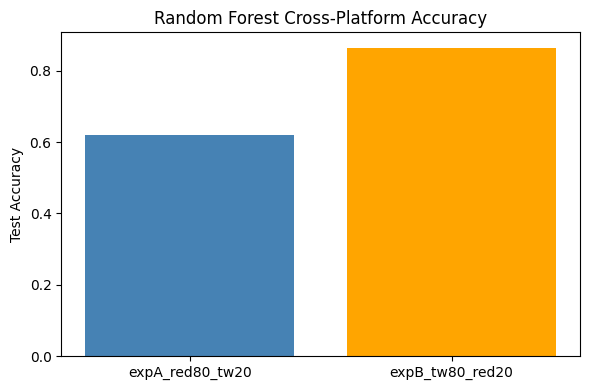

Saved summary plot → c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\output\rf\rf_accuracy_summary.png


In [10]:
summary = []
for r in results:
    with open(r["metrics_path"]) as f:
        m = json.load(f)
    summary.append({
        "Experiment": r["name"],
        "Val Acc": round(r["val_acc"], 4),
        "Test Acc": round(r["test_acc"], 4),
        "Precision (1)": round(m["1"]["precision"], 3),
        "Recall (1)": round(m["1"]["recall"], 3),
        "F1 (1)": round(m["1"]["f1-score"], 3)
    })

df_summary = pd.DataFrame(summary)
print(df_summary)

# Simple bar plot of test accuracy
plt.figure(figsize=(6,4))
plt.bar(df_summary["Experiment"], df_summary["Test Acc"], color=["steelblue","orange"])
plt.title("Random Forest Cross-Platform Accuracy")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plot_path = OUT_DIR / "rf_accuracy_summary.png"
plt.savefig(plot_path, dpi=300)
plt.show()
print("Saved summary plot →", plot_path)


## 6. Cross-Platform Accuracy Comparison
Computes and prints all four combinations of training/testing domains using saved models.

In [ ]:
from pathlib import Path
import pandas as pd, numpy as np, re, joblib
from sklearn.metrics import accuracy_score
from sklearn.utils import shuffle

# --- repo roots and paths (works whether you're in repo/ or repo/notebooks/)
CWD  = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DATA_BASE   = ROOT / "data" / "raw"
REDDIT_DIR  = DATA_BASE / "reddit"
TWITTER_CSV = DATA_BASE / "Mental-Health-Twitter.csv"

EXP_A_DIR = ROOT / "data" / "preprocessed" / "experiments" / "expA_red80_tw20"
EXP_B_DIR = ROOT / "data" / "preprocessed" / "experiments" / "expB_tw80_red20"
MODEL_A   = ROOT / "models" / "rf" / "expA_red80_tw20_rf_model.pkl"
VEC_A     = EXP_A_DIR / "tfidf_rf.pkl"
MODEL_B   = ROOT / "models" / "rf" / "expB_tw80_red20_rf_model.pkl"
VEC_B     = EXP_B_DIR / "tfidf_rf.pkl"

# --- quick asserts so failures are obvious
def must_exist(p: Path):
    if not p.exists():
        raise FileNotFoundError(f"Missing: {p}")
for p in [REDDIT_DIR, TWITTER_CSV, MODEL_A, VEC_A, MODEL_B, VEC_B]:
    must_exist(p)

# --- list a couple of files to confirm the folder we will read
print("CWD:", CWD)
print("Using Reddit folder:", REDDIT_DIR)
print("Reddit CSV count:", len(list(REDDIT_DIR.glob("*.csv"))))
print("Twitter CSV:", TWITTER_CSV.name)

# --- define which Reddit CSVs are positive vs control
MH_SUBS = {
    "addiction_2019_features_tfidf_256.csv",
    "adhd_2019_features_tfidf_256.csv",
    "alcoholism_2019_features_tfidf_256.csv",
    "anxiety_2019_features_tfidf_256.csv",
    "mentalhealth_2019_features_tfidf_256.csv",
    "suicidewatch_2019_features_tfidf_256.csv",
}
CTRL_SUBS = {
    "jokes_2019_features_tfidf_256.csv",
    "fitness_2019_features_tfidf_256.csv",
    "meditation_2019_features_tfidf_256.csv",
    "relationships_2019_features_tfidf_256.csv",
    "teaching_2019_features_tfidf_256.csv",
    "conspiracy_2019_features_tfidf_256.csv",
}

SEED = 42
def clean_text(t: str) -> str:
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-zA-Z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t.lower()

def load_reddit_pure():
    rows = []
    for fname in sorted(MH_SUBS):
        f = REDDIT_DIR / fname
        must_exist(f)
        df = pd.read_csv(f, encoding="utf-8", low_memory=False)
        rows.append(pd.DataFrame({"text": df["post"].astype(str), "label": 1}))
    for fname in sorted(CTRL_SUBS):
        f = REDDIT_DIR / fname
        must_exist(f)
        df = pd.read_csv(f, encoding="utf-8", low_memory=False)
        rows.append(pd.DataFrame({"text": df["post"].astype(str), "label": 0}))
    out = pd.concat(rows, ignore_index=True)
    return shuffle(out, random_state=SEED).reset_index(drop=True)

def load_twitter_pure():
    must_exist(TWITTER_CSV)
    df = pd.read_csv(TWITTER_CSV, encoding="utf-8", low_memory=False)
    # expects columns: post_text, label (0/1)
    df = df.rename(columns={"post_text": "text"})
    df["text"]  = df["text"].astype(str)
    df["label"] = df["label"].astype(int)
    return shuffle(df[["text","label"]], random_state=SEED).reset_index(drop=True)

def evaluate(model_path: Path, vec_path: Path, test_texts: pd.Series, test_y: np.ndarray) -> float:
    model = joblib.load(model_path)
    vec   = joblib.load(vec_path)
    X     = vec.transform(test_texts.map(clean_text))
    yhat  = model.predict(X)
    return float(accuracy_score(test_y, yhat))

# --- load tests and compute four combos
reddit_test  = load_reddit_pure()
twitter_test = load_twitter_pure()

res = []
acc_rr = evaluate(MODEL_A, VEC_A, reddit_test["text"],  reddit_test["label"].to_numpy())
acc_rt = evaluate(MODEL_A, VEC_A, twitter_test["text"], twitter_test["label"].to_numpy())
res += [{"Train Domain":"Reddit",  "Test Domain":"Reddit",  "Accuracy": round(acc_rr,4)},
        {"Train Domain":"Reddit",  "Test Domain":"Twitter", "Accuracy": round(acc_rt,4)}]

acc_tt = evaluate(MODEL_B, VEC_B, twitter_test["text"], twitter_test["label"].to_numpy())
acc_tr = evaluate(MODEL_B, VEC_B, reddit_test["text"],  reddit_test["label"].to_numpy())
res += [{"Train Domain":"Twitter", "Test Domain":"Twitter", "Accuracy": round(acc_tt,4)},
        {"Train Domain":"Twitter", "Test Domain":"Reddit",  "Accuracy": round(acc_tr,4)}]

summary = pd.DataFrame(res)
print("\n", summary.to_string(index=False))

# sanity prints
print("\nBalances:",
      "\n  Reddit  :", reddit_test['label'].value_counts(normalize=True).round(3).to_dict(),
      "\n  Twitter :", twitter_test['label'].value_counts(normalize=True).round(3).to_dict())


CWD: c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\notebooks
Using Reddit folder: c:\Users\halab_iqyec8m\crossplatform-mentalhealth-ml\data\raw\reddit
Reddit CSV count: 12
Twitter CSV: Mental-Health-Twitter.csv

 Train Domain Test Domain  Accuracy
      Reddit      Reddit    0.9803
      Reddit     Twitter    0.8707
     Twitter     Twitter    0.9079
     Twitter      Reddit    0.8673

Balances: 
  Reddit  : {0: 0.6, 1: 0.4} 
  Twitter : {0: 0.5, 1: 0.5}
